In [1]:
import pandas as pd

# Create sample movie reviews
sample_reviews = pd.DataFrame({
    "review_id": [1, 2, 3, 4, 5, 6],

    "text": [
        "The movie was not good at all.",
        "I loved how the movie wasted two hours of my life.",
        "The story was boring and the acting was weak.",
        "A wonderful film with excellent performances.",
        "The movie was excellent from beginning to end.",
        "The film was terrible and disappointing."
    ],

    "true_label": [
        "negative",
        "negative",
        "negative",
        "positive",
        "positive",
        "negative"
    ],

    "predicted_label": [
        "positive",
        "positive",
        "negative",
        "positive",
        "negative",
        "negative"
    ]
})

# Display sample data
print(sample_reviews.to_string(index=False))

print("\nTotal Reviews:", len(sample_reviews))

 review_id                                               text true_label predicted_label
         1                     The movie was not good at all.   negative        positive
         2 I loved how the movie wasted two hours of my life.   negative        positive
         3      The story was boring and the acting was weak.   negative        negative
         4      A wonderful film with excellent performances.   positive        positive
         5     The movie was excellent from beginning to end.   positive        negative
         6           The film was terrible and disappointing.   negative        negative

Total Reviews: 6


In [2]:
# Find incorrect predictions
errors = sample_reviews[
    sample_reviews["true_label"] != sample_reviews["predicted_label"]
].copy()

# Display incorrect predictions
print("Incorrect Predictions:")
print(errors.to_string(index=False))

print("\nTotal Errors:", len(errors))

Incorrect Predictions:
 review_id                                               text true_label predicted_label
         1                     The movie was not good at all.   negative        positive
         2 I loved how the movie wasted two hours of my life.   negative        positive
         5     The movie was excellent from beginning to end.   positive        negative

Total Errors: 3


In [4]:
# Define error categories manually for sample data
category_map = {
    1: "Negation",
    2: "Sarcasm",
    5: "Missed Positive Sentiment"
}

explanation_map = {
    1: "The phrase 'not good' reverses the positive meaning.",
    2: "The word 'loved' is used sarcastically with 'wasted two hours'.",
    5: "The review contains positive words, but the model predicted negative."
}

# Add error categories
errors["error_type"] = errors["review_id"].map(category_map)

# Add explanations
errors["explanation"] = errors["review_id"].map(explanation_map)

# Display error analysis
print(errors[
    ["review_id", "text", "error_type", "explanation"]
].to_string(index=False))

 review_id                                               text                error_type                                                           explanation
         1                     The movie was not good at all.                  Negation                  The phrase 'not good' reverses the positive meaning.
         2 I loved how the movie wasted two hours of my life.                   Sarcasm       The word 'loved' is used sarcastically with 'wasted two hours'.
         5     The movie was excellent from beginning to end. Missed Positive Sentiment The review contains positive words, but the model predicted negative.


In [5]:
from IPython.display import display as show_table

show_table(
    errors[[
        "review_id",
        "text",
        "error_type",
        "explanation"
    ]]
)

,review_id,text,error_type,explanation
0,1,The movie was not good at all.,Negation,The phrase 'not good' reverses the positive me...
1,2,I loved how the movie wasted two hours of my l...,Sarcasm,The word 'loved' is used sarcastically with 'w...
4,5,The movie was excellent from beginning to end.,Missed Positive Sentiment,"The review contains positive words, but the mo..."


In [6]:
# Show complete text without truncation
pd.set_option("display.max_colwidth", None)

for _, row in errors.iterrows():
    print("Review ID:", row["review_id"])
    print("Review:", row["text"])
    print("Error Type:", row["error_type"])
    print("Explanation:", row["explanation"])
    print("-" * 80)

Review ID: 1
Review: The movie was not good at all.
Error Type: Negation
Explanation: The phrase 'not good' reverses the positive meaning.
--------------------------------------------------------------------------------
Review ID: 2
Review: I loved how the movie wasted two hours of my life.
Error Type: Sarcasm
Explanation: The word 'loved' is used sarcastically with 'wasted two hours'.
--------------------------------------------------------------------------------
Review ID: 5
Review: The movie was excellent from beginning to end.
Error Type: Missed Positive Sentiment
Explanation: The review contains positive words, but the model predicted negative.
--------------------------------------------------------------------------------


In [7]:
# Save error analysis to CSV
errors.to_csv("error_analysis.csv", index=False, encoding="utf-8-sig")

print("Error analysis saved successfully!")

Error analysis saved successfully!


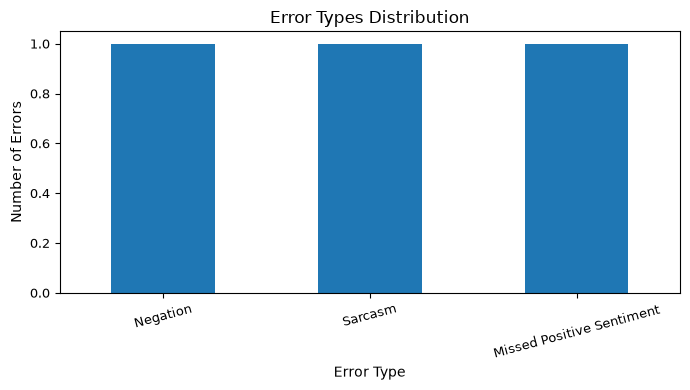

In [10]:
import matplotlib.pyplot as plt

error_counts = errors["error_type"].value_counts()

plt.figure(figsize=(7, 4))

error_counts.plot(kind="bar", width=0.5)

plt.title("Error Types Distribution", fontsize=12)
plt.xlabel("Error Type", fontsize=10)
plt.ylabel("Number of Errors", fontsize=10)

plt.xticks(rotation=15, fontsize=9)
plt.yticks(fontsize=9)

plt.tight_layout()

plt.savefig(
    "error_types_distribution.png",
    dpi=120,
    bbox_inches="tight"
)

plt.show()

## Error Analysis Results

The model produced 3 incorrect predictions out of 6 movie reviews.

The errors were divided into three categories:
- Negation: 1 error.
- Sarcasm: 1 error.
- Missed Positive Sentiment: 1 error.

Each category represents 33.33% of the total errors.

The results show that the model has difficulties
understanding negation, sarcasm, and positive sentiment.

More data is needed to improve the model's performance.

## Recommendations for Improvement

1. Negation Handling:
Improve the model's ability to understand negative words such as "not" and "never".

2. Sarcasm Detection:
Add more sarcastic reviews to the dataset to help the model recognize sarcasm.

3. Positive Sentiment Detection:
Include more positive reviews and improve the recognition of positive expressions.

## Limitations

- The analysis contains only 6 movie reviews.
- The small dataset may not represent all types of movie reviews.
- More testing is required to evaluate the model reliably.

## Conclusion

The error analysis helped identify the main weaknesses of the sentiment analysis model.

The model made 3 incorrect predictions out of 6 reviews.

The main errors were related to negation, sarcasm, and missed positive sentiment.

Improving text understanding and using a larger dataset may help increase the model's accuracy.

Further evaluation is needed to confirm the improvements.

In [11]:

import pandas as pd
from pathlib import Path

# Check prediction files
unigram_file = Path("unigram_predictions.csv")
bigram_file = Path("bigram_predictions.csv")

if not unigram_file.exists() or not bigram_file.exists():
    print("Waiting for prediction files...")
    
else:
    # Load prediction files
    unigram = pd.read_csv(unigram_file)
    bigram = pd.read_csv(bigram_file)

    # Required columns
    required_columns = [
        "review_id",
        "text",
        "true_label",
        "predicted_label"
    ]

    # Validate and prepare data
    def prepare_data(data, model_name):

        missing = [
            col for col in required_columns
            if col not in data.columns
        ]

        if missing:
            raise ValueError(
                f"{model_name} missing columns: {missing}"
            )

        data = data.copy()

        if data[required_columns].isnull().any().any():
            raise ValueError(
                f"{model_name} contains missing values!"
            )

        data["review_id"] = (
            data["review_id"].astype(str).str.strip()
        )

        if data["review_id"].duplicated().any():
            raise ValueError(
                f"{model_name} has duplicate review IDs!"
            )

        data["text"] = data["text"].astype(str).str.strip()

        for col in ["true_label", "predicted_label"]:
            data[col] = (
                data[col].astype(str).str.strip().str.lower()
            )

            valid_labels = {"positive", "negative"}

            if not set(data[col]).issubset(valid_labels):
                raise ValueError(
                    f"Invalid labels in {model_name}!"
                )

        return data

    unigram = prepare_data(unigram, "Unigram")
    bigram = prepare_data(bigram, "Bigram")

    # Check matching test reviews
    if set(unigram["review_id"]) != set(bigram["review_id"]):
        raise ValueError(
            "The two models must use the same test reviews!"
        )

    # Check matching actual labels and review texts
    check = unigram.merge(
        bigram,
        on="review_id",
        suffixes=("_unigram", "_bigram"),
        validate="one_to_one"
    )

    if not (
        check["true_label_unigram"]
        == check["true_label_bigram"]
    ).all():
        raise ValueError("True labels do not match!")

    if not (
        check["text_unigram"]
        == check["text_bigram"]
    ).all():
        raise ValueError("Review texts do not match!")

    # Extract incorrect predictions
    unigram_errors = unigram[
        unigram["true_label"] != unigram["predicted_label"]
    ].copy()

    bigram_errors = bigram[
        bigram["true_label"] != bigram["predicted_label"]
    ].copy()

    # Identify models
    unigram_errors["model"] = "Unigram"
    bigram_errors["model"] = "Bigram"

    # Combine errors
    errors = pd.concat(
        [unigram_errors, bigram_errors],
        ignore_index=True
    )

    # Select analysis columns
    errors = errors[
        [
            "model",
            "review_id",
            "text",
            "true_label",
            "predicted_label"
        ]
    ]

    # Add manual analysis columns
    errors["error_type"] = ""
    errors["explanation"] = ""

    # Display error statistics
    print("ERROR ANALYSIS RESULTS")
    print("----------------------")
    print("Unigram Errors:", len(unigram_errors))
    print("Bigram Errors:", len(bigram_errors))
    print("Total Errors:", len(errors))

    # Save error analysis
    errors.to_csv(
        "error_analysis_results.csv",
        index=False,
        encoding="utf-8-sig"
    )

    # Display first 20 errors
    pd.set_option("display.max_colwidth", None)

    print("\nFirst 20 Errors:")
    display(errors.head(20))

    if len(errors) >= 20:
        print("\nAt least 20 error cases are available.")
    else:
        print("\nMore error cases are needed to reach 20.")
    
    print("\nError analysis file saved successfully!")


Waiting for prediction files...


In [12]:
import re
import html

# Clean movie reviews
def clean_review(text):

    if pd.isna(text):
        return ""

    text = html.unescape(str(text))

    # Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Remove unnecessary notes and chat labels
    text = re.sub(
        r'\b(User|Assistant|ChatGPT|System)\s*:',
        '',
        text,
        flags=re.IGNORECASE
    )

    text = re.sub(
        r'\b(Note|Notes|Comment|Comments)\s*:[^\n]*',
        '',
        text,
        flags=re.IGNORECASE
    )

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Apply cleaning
sample_reviews["text"] = sample_reviews["text"].apply(clean_review)

# Remove empty reviews and duplicates
sample_reviews = sample_reviews[
    sample_reviews["text"] != ""
].drop_duplicates(subset=["text"])

sample_reviews = sample_reviews.reset_index(drop=True)

# Save cleaned data
sample_reviews.to_csv(
    "cleaned_reviews.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Data cleaning completed successfully!")
print("Total reviews:", len(sample_reviews))

display(sample_reviews)

Data cleaning completed successfully!
Total reviews: 6


,review_id,text,true_label,predicted_label
0,1,The movie was not good at all.,negative,positive
1,2,I loved how the movie wasted two hours of my life.,negative,positive
2,3,The story was boring and the acting was weak.,negative,negative
3,4,A wonderful film with excellent performances.,positive,positive
4,5,The movie was excellent from beginning to end.,positive,negative
5,6,The film was terrible and disappointing.,negative,negative


In [1]:

import pandas as pd

# Load actual prediction files
unigram_check = pd.read_csv("unigram_predictions.csv")
bigram_check = pd.read_csv("bigram_predictions.csv")

# Inspect Unigram file
print("UNIGRAM COLUMNS:")
print(unigram_check.columns.tolist())
print("\nUNIGRAM FIRST 5 ROWS:")
print(unigram_check.head().to_string(index=False))

# Inspect Bigram file
print("\nBIGRAM COLUMNS:")
print(bigram_check.columns.tolist())
print("\nBIGRAM FIRST 5 ROWS:")
print(bigram_check.head().to_string(index=False))


UNIGRAM COLUMNS:
['review_id', 'true_label', 'predicted_label']

UNIGRAM FIRST 5 ROWS:
          review_id true_label predicted_label
neg/cv001_19502.txt        neg             neg
neg/cv004_12641.txt        neg             neg
neg/cv013_10494.txt        neg             neg
neg/cv014_15600.txt        neg             neg
 neg/cv020_9234.txt        neg             neg

BIGRAM COLUMNS:
['review_id', 'true_label', 'predicted_label']

BIGRAM FIRST 5 ROWS:
          review_id true_label predicted_label
neg/cv748_14044.txt   negative        negative
 neg/cv020_9234.txt   negative        negative
pos/cv088_24113.txt   positive        positive
neg/cv466_20092.txt   negative        positive
neg/cv491_12992.txt   negative        negative


In [2]:

from nltk.corpus import movie_reviews

# Get a sample review ID
sample_id = str(
    unigram_check.iloc[0]["review_id"]
).strip()

# Check NLTK Movie Reviews corpus
try:
    available_ids = set(movie_reviews.fileids())

    print("Total reviews in NLTK:", len(available_ids))
    print("Sample review ID:", sample_id)
    print("Review ID found:", sample_id in available_ids)

    if sample_id in available_ids:
        print("\nOriginal Review Text:")
        print(movie_reviews.raw(sample_id)[:1000])
    else:
        print("\nReview ID was not found in the corpus.")

except LookupError:
    print("NLTK Movie Reviews corpus is not downloaded.")


NLTK Movie Reviews corpus is not downloaded.


In [3]:

import nltk

# Download Movie Reviews dataset
download_status = nltk.download("movie_reviews")

print("Download successful:", download_status)


[nltk_data] Downloading package movie_reviews to
[nltk_data]     C:\Users\g7fr1\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\movie_reviews.zip.


Download successful: True


In [4]:

import pandas as pd
import re
from nltk.corpus import movie_reviews

# Load prediction files
unigram = pd.read_csv("unigram_predictions.csv")
bigram = pd.read_csv("bigram_predictions.csv")

# Normalize labels
label_mapping = {
    "neg": "negative",
    "pos": "positive"
}

for data in [unigram, bigram]:
    data["review_id"] = data["review_id"].astype(str).str.strip()

    for col in ["true_label", "predicted_label"]:
        data[col] = (
            data[col].astype(str)
            .str.strip().str.lower()
            .replace(label_mapping)
        )

# Check duplicate IDs
if unigram["review_id"].duplicated().any():
    raise ValueError("Duplicate IDs in Unigram!")

if bigram["review_id"].duplicated().any():
    raise ValueError("Duplicate IDs in Bigram!")

# Match review IDs
if set(unigram["review_id"]) != set(bigram["review_id"]):
    raise ValueError("Review IDs do not match!")

# Check corpus availability
available_ids = set(movie_reviews.fileids())

missing_ids = (
    set(unigram["review_id"]) - available_ids
)

if missing_ids:
    raise ValueError(
        f"Some review IDs were not found: {list(missing_ids)[:5]}"
    )

# Rename columns
unigram = unigram.rename(columns={
    "true_label": "true_label_unigram",
    "predicted_label": "predicted_unigram"
})

bigram = bigram.rename(columns={
    "true_label": "true_label_bigram",
    "predicted_label": "predicted_bigram"
})

# Merge both models
combined = pd.merge(
    unigram,
    bigram,
    on="review_id",
    validate="one_to_one"
)

# Check true labels
if not (
    combined["true_label_unigram"]
    == combined["true_label_bigram"]
).all():
    raise ValueError("True labels do not match!")

combined["true_label"] = combined["true_label_unigram"]

# Retrieve original review texts
combined["text"] = combined["review_id"].apply(
    movie_reviews.raw
)

# Identify errors
combined["unigram_error"] = (
    combined["true_label"] != combined["predicted_unigram"]
)

combined["bigram_error"] = (
    combined["true_label"] != combined["predicted_bigram"]
)

combined["both_wrong"] = (
    combined["unigram_error"] & combined["bigram_error"]
)

# Identify possible linguistic error cues
def identify_error_cues(text):

    cues = []

    patterns = {
        "Negation": r"\b(not|no|never|n't|neither|nor|hardly|barely|without)\b",
        "Contrast": r"\b(but|however|although|though|yet|despite|whereas)\b",
        "Intensifiers": r"\b(very|really|extremely|highly|absolutely|completely)\b",
        "Possible irony": r"\b(yeah right|as if|supposedly)\b"
    }

    text = text.lower()

    for cue, pattern in patterns.items():
        if re.search(pattern, text):
            cues.append(cue)

    return ", ".join(cues) if cues else "Needs manual review"

# Select actual errors
errors = combined[
    combined["unigram_error"] | combined["bigram_error"]
].copy()

errors["possible_error_cues"] = errors["text"].apply(
    identify_error_cues
)

# Prioritize reviews where both models failed
errors = errors.sort_values(
    "both_wrong",
    ascending=False
)

# Print summary
print("ERROR ANALYSIS SUMMARY")
print("----------------------")
print("Total reviews:", len(combined))
print("Unigram errors:", combined["unigram_error"].sum())
print("Bigram errors:", combined["bigram_error"].sum())
print("Both models wrong:", combined["both_wrong"].sum())
print(
    "Unigram only errors:",
    (
        combined["unigram_error"]
        & ~combined["bigram_error"]
    ).sum()
)
print(
    "Bigram only errors:",
    (
        combined["bigram_error"]
        & ~combined["unigram_error"]
    ).sum()
)

# Extract 20 real error examples
sample_20 = errors.head(20).copy()

sample_20["text_preview"] = (
    sample_20["text"].str.replace(r"\s+", " ", regex=True)
    .str.slice(0, 500)
)

print("\nFIRST 20 ERROR EXAMPLES")

display(sample_20[[
    "review_id",
    "text_preview",
    "true_label",
    "predicted_unigram",
    "predicted_bigram",
    "unigram_error",
    "bigram_error",
    "possible_error_cues"
]])

# Save full error analysis
errors.to_csv(
    "error_analysis_results.csv",
    index=False,
    encoding="utf-8-sig"
)

sample_20.to_csv(
    "error_analysis_sample_20.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nError analysis files saved successfully!")


ERROR ANALYSIS SUMMARY
----------------------
Total reviews: 400
Unigram errors: 72
Bigram errors: 56
Both models wrong: 50
Unigram only errors: 22
Bigram only errors: 6

FIRST 20 ERROR EXAMPLES


,review_id,text_preview,true_label,predicted_unigram,predicted_bigram,unigram_error,bigram_error,possible_error_cues
7,neg/cv032_23718.txt,hong kong cinema has been going through a bad ...,negative,positive,positive,True,True,"Negation, Contrast, Intensifiers, Possible irony"
127,neg/cv646_16817.txt,""" with all that education , you should know w...",negative,positive,positive,True,True,"Negation, Contrast"
139,neg/cv700_23163.txt,""" the beach "" is a structurally confusing fil...",negative,positive,positive,True,True,"Negation, Contrast, Intensifiers, Possible irony"
146,neg/cv727_5006.txt,"girl 6 is , in a word , a mess . i was never a...",negative,positive,positive,True,True,"Negation, Contrast, Intensifiers"
150,neg/cv742_8279.txt,"when i was nine , i started buying the coolest...",negative,positive,positive,True,True,"Negation, Contrast, Intensifiers"
151,neg/cv747_18189.txt,"in 1970s , many european intellectuals , espec...",negative,positive,positive,True,True,"Negation, Contrast, Intensifiers, Possible irony"
167,neg/cv805_21128.txt,my first exposure to the nightmare on elm stre...,negative,positive,positive,True,True,"Negation, Contrast, Intensifiers, Possible irony"
8,neg/cv034_29446.txt,if you're into watching near on two hours of b...,negative,positive,positive,True,True,"Negation, Contrast"
173,neg/cv838_25886.txt,"in our time . in our modern world , where the ...",negative,positive,positive,True,True,"Negation, Contrast, Intensifiers"
181,neg/cv862_15924.txt,the original babe gets my vote as the best fam...,negative,positive,positive,True,True,"Negation, Contrast, Intensifiers, Possible irony"



Error analysis files saved successfully!


In [5]:

from IPython.display import display

# Errors fixed by Bigram
unigram_only = errors[
    errors["unigram_error"] &
    ~errors["bigram_error"]
].copy()

# Errors made only by Bigram
bigram_only = errors[
    errors["bigram_error"] &
    ~errors["unigram_error"]
].copy()

print("CASES FIXED BY BIGRAM:", len(unigram_only))

display(unigram_only[[
    "review_id",
    "text",
    "true_label",
    "predicted_unigram",
    "predicted_bigram",
    "possible_error_cues"
]].head(5))

print("\nCASES WHERE BIGRAM FAILED:", len(bigram_only))

display(bigram_only[[
    "review_id",
    "text",
    "true_label",
    "predicted_unigram",
    "predicted_bigram",
    "possible_error_cues"
]])

# Save both groups
unigram_only.to_csv(
    "unigram_only_errors.csv",
    index=False,
    encoding="utf-8-sig"
)

bigram_only.to_csv(
    "bigram_only_errors.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nModel-specific error analysis saved!")


CASES FIXED BY BIGRAM: 22


,review_id,text,true_label,predicted_unigram,predicted_bigram,possible_error_cues
377,pos/cv917_29715.txt,plot : a dude and his brother are driving cros...,positive,negative,positive,"Negation, Contrast, Intensifiers"
24,neg/cv102_8306.txt,"ever since wargames , the first real computer ...",negative,positive,negative,"Negation, Contrast, Intensifiers"
354,pos/cv831_14689.txt,razor blade smile running as part of the vanco...,positive,negative,positive,"Negation, Contrast, Intensifiers"
397,pos/cv987_6965.txt,trees lounge is the directoral debut from one ...,positive,negative,positive,"Negation, Contrast"
353,pos/cv827_18331.txt,it was only a matter of time before a dilbert-...,positive,negative,positive,"Negation, Contrast, Intensifiers"



CASES WHERE BIGRAM FAILED: 6


,review_id,text,true_label,predicted_unigram,predicted_bigram,possible_error_cues
371,pos/cv901_11017.txt,the start of this movie reminded me of parts f...,positive,positive,negative,"Negation, Contrast, Intensifiers"
32,neg/cv156_11119.txt,senseless ( r ) marlon wayans is a very talent...,negative,negative,positive,"Negation, Contrast, Intensifiers"
37,neg/cv170_29808.txt,mulholland drive did very well at the cannes f...,negative,negative,positive,"Negation, Contrast, Intensifiers"
166,neg/cv804_11763.txt,"for his directoral debut , gary oldman chose a...",negative,negative,positive,"Negation, Contrast, Intensifiers"
64,neg/cv330_29675.txt,august and september are a wasteland when it c...,negative,negative,positive,"Negation, Contrast, Intensifiers"
216,pos/cv103_11021.txt,i think that any competent member of the human...,positive,positive,negative,"Negation, Contrast, Intensifiers"



Model-specific error analysis saved!


In [6]:

# Inspect full review texts

print("CASES FIXED BY BIGRAM")
print("=" * 60)

for _, row in unigram_only.head(5).iterrows():
    print("\nReview ID:", row["review_id"])
    print("True label:", row["true_label"])
    print("Unigram:", row["predicted_unigram"])
    print("Bigram:", row["predicted_bigram"])
    print("Full review:")
    print(row["text"][:1500])
    print("-" * 60)


print("\nCASES WHERE BIGRAM FAILED")
print("=" * 60)

for _, row in bigram_only.iterrows():
    print("\nReview ID:", row["review_id"])
    print("True label:", row["true_label"])
    print("Unigram:", row["predicted_unigram"])
    print("Bigram:", row["predicted_bigram"])
    print("Full review:")
    print(row["text"][:1500])
    print("-" * 60)


CASES FIXED BY BIGRAM

Review ID: pos/cv917_29715.txt
True label: positive
Unigram: negative
Bigram: positive
Full review:
plot : a dude and his brother are driving cross-country and decide to fool around with a trucker on their cb radio . 
it isn't long before their little prank gets someone put into a coma ( long story ) and the next thing you know , the trucker is following them too . 
lotsa nuttiness ensues and then , they pick up their other friend , venna , a girl who the dude has a crush on . 
but what's this . . . ? 
the trucker is still on their tail and is now harassing all three of the young whippersnappers . . . ? 
you bet ! 
buckle up , dorothy . . . this is gonna be one bumpy ride ! 
critique : a good ol' time at the movies ! 
here's a film that actually gives away most of its plotline in its trailer and doesn't really bring anything " new " to the forefront ( if you've seen flicks like duel and breakdown , you've crossed this path before ) , but still manages to entertai

# Final Error Analysis and Model Comparison

## 1. Overall Performance

The error analysis shows that the Bigram model performed better than the Unigram model.

Out of 400 test reviews, the Unigram model made 72 classification errors, while the Bigram model made only 56 errors.

The Bigram model corrected 22 errors made by the Unigram model, but it also introduced 6 new errors. Therefore, it achieved a net improvement of 16 correctly classified reviews.

## 2. Cases Fixed by Bigram

The Bigram model successfully corrected several reviews that the Unigram model classified incorrectly.

For example:
- Some positive reviews contained negative words such as "bad", "boring", and "loser", but their overall meaning was positive.
- The Bigram model performed better on reviews containing positive expressions such as "good time", "excellent job", and "very good".

This suggests that considering pairs of words can help improve sentiment classification when individual words may be misleading.

## 3. Cases Where Bigram Failed

The Bigram model made 6 classification errors that the Unigram model classified correctly.

The main possible reasons include:

- **Sarcasm and irony:** Some reviews used positive words sarcastically, which confused the model.
- **Mixed sentiment:** Some reviews contained both positive and negative opinions.
- **Negation and context:** The model sometimes failed to interpret the overall meaning of a sentence.
- **Long reviews:** The overall sentiment was not always represented by individual word pairs.

For example, the review of "Max Keeble's Big Move" contained sarcastic positive expressions, which led to an incorrect positive prediction.

## 4. Conclusion

Overall, the Bigram model achieved better classification performance than the Unigram model.

Its accuracy increased from 82% to 86%, while the total number of errors decreased from 72 to 56.

However, both models still struggled with sarcasm, mixed opinions, and complex sentence meanings.

Therefore, the Bigram model is the better-performing model in this experiment, although further improvements are needed to handle contextual meaning more effectively.


In [7]:

import nltk
import pandas as pd
import numpy as np
from nltk.corpus import movie_reviews

# Download the original dataset if needed
nltk.download("movie_reviews", quiet=True)

# Load prediction files
unigram = pd.read_csv("unigram_predictions.csv")
bigram = pd.read_csv("bigram_predictions.csv")

# Normalize sentiment labels
def normalize_label(label):
    label = str(label).strip().lower()
    return {"neg": "negative", "pos": "positive"}.get(label, label)

for df in [unigram, bigram]:
    df["true_label"] = df["true_label"].apply(normalize_label)
    df["predicted_label"] = df["predicted_label"].apply(normalize_label)

# Retrieve original review texts
fileids = movie_reviews.fileids()

reviews = pd.DataFrame({
    "review_id": fileids,
    "text": [movie_reviews.raw(fid) for fid in fileids]
})

# Merge both models
unigram = unigram.rename(columns={
    "true_label": "true_label_unigram",
    "predicted_label": "predicted_unigram"
})

bigram = bigram.rename(columns={
    "true_label": "true_label_bigram",
    "predicted_label": "predicted_bigram"
})

comparison = unigram.merge(
    bigram,
    on="review_id",
    validate="one_to_one"
)

# Verify true labels
assert (
    comparison["true_label_unigram"] ==
    comparison["true_label_bigram"]
).all(), "True labels do not match!"

# Add original review texts
comparison = comparison.merge(
    reviews,
    on="review_id",
    how="left",
    validate="one_to_one"
)

assert comparison["text"].notna().all(), "Some review texts are missing!"

# Identify model errors
comparison["unigram_error"] = (
    comparison["true_label_unigram"] !=
    comparison["predicted_unigram"]
)

comparison["bigram_error"] = (
    comparison["true_label_bigram"] !=
    comparison["predicted_bigram"]
)

# Classify comparison groups
conditions = [
    comparison["unigram_error"] & comparison["bigram_error"],
    comparison["unigram_error"] & ~comparison["bigram_error"],
    ~comparison["unigram_error"] & comparison["bigram_error"]
]

choices = [
    "Both models wrong",
    "Unigram only wrong",
    "Bigram only wrong"
]

comparison["error_group"] = np.select(
    conditions,
    choices,
    default="Both correct"
)

# Keep all misclassified reviews
errors = comparison[
    comparison["error_group"] != "Both correct"
].copy()

# Select 20 representative errors
sample_plan = {
    "Both models wrong": 10,
    "Unigram only wrong": 5,
    "Bigram only wrong": 5
}

selected_parts = []

for group, count in sample_plan.items():
    group_data = errors[errors["error_group"] == group]
    selected_parts.append(
        group_data.sample(n=count, random_state=42)
    )

selected = pd.concat(selected_parts)

# Prepare manual analysis columns
selected["manual_error_type"] = ""
selected["manual_reason"] = ""

# Save results
errors.to_csv(
    "all_misclassified_reviews_with_text.csv",
    index=False,
    encoding="utf-8-sig"
)

selected.to_csv(
    "error_analysis_sample_20.csv",
    index=False,
    encoding="utf-8-sig"
)

print("ERROR ANALYSIS DATA PREPARED SUCCESSFULLY!")
print("Total test reviews:", len(comparison))
print("Unigram errors:", comparison["unigram_error"].sum())
print("Bigram errors:", comparison["bigram_error"].sum())
print("Unique misclassified reviews:", len(errors))
print("\nSelected 20 reviews:")
print(selected["error_group"].value_counts())
print("\nFiles saved successfully!")


ERROR ANALYSIS DATA PREPARED SUCCESSFULLY!
Total test reviews: 400
Unigram errors: 72
Bigram errors: 56
Unique misclassified reviews: 78

Selected 20 reviews:
error_group
Both models wrong     10
Unigram only wrong     5
Bigram only wrong      5
Name: count, dtype: int64

Files saved successfully!


In [8]:
import pandas as pd

data = pd.read_csv("error_analysis_sample_20_annotated.csv")

print("Manual Error Analysis")
print("Total reviews:", len(data))

display(data[[
    "review_id",
    "error_group",
    "manual_error_type",
    "manual_reason"
]])

Manual Error Analysis
Total reviews: 20


,review_id,error_group,manual_error_type,manual_reason
0,neg/cv427_11693.txt,Both models wrong,Mixed sentiment / contrast,The review is strongly negative overall: it ca...
1,pos/cv419_13394.txt,Both models wrong,Mixed sentiment / contrast,The review begins with criticism of the story ...
2,neg/cv838_25886.txt,Both models wrong,Mixed sentiment / contrast,"The reviewer criticizes the film as confusing,..."
3,pos/cv841_3967.txt,Both models wrong,Sarcasm / irony,The review uses negative-sounding words about ...
4,neg/cv461_21124.txt,Both models wrong,Mixed sentiment / contrast,The review repeatedly describes the film as la...
5,pos/cv937_9811.txt,Both models wrong,Sentiment reversal / temporal shift,The reviewer initially dislikes the title and ...
6,neg/cv742_8279.txt,Both models wrong,Mixed sentiment / contrast,The review recalls childhood enthusiasm for th...
7,neg/cv727_5006.txt,Both models wrong,Mixed sentiment / contrast,"The reviewer calls the film a mess, says its n..."
8,neg/cv880_29629.txt,Both models wrong,Mixed sentiment / contrast,"The text mentions a brilliant art dealer, roma..."
9,neg/cv475_22978.txt,Both models wrong,Mixed sentiment / contrast,The reviewer acknowledges that the franchise c...


In [9]:
# Error Analysis Statistics

print("ERROR GROUP DISTRIBUTION")
display(data["error_group"].value_counts())

print("\nMANUAL ERROR TYPE DISTRIBUTION")

summary = data["manual_error_type"].value_counts().reset_index()

summary.columns = ["Error Type", "Count"]

summary["Percentage"] = (
    summary["Count"] / len(data) * 100
).round(2)

display(summary)

# Save summary
summary.to_csv(
    "manual_error_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Summary saved successfully!")

ERROR GROUP DISTRIBUTION


error_group
Both models wrong     10
Unigram only wrong     5
Bigram only wrong      5
Name: count, dtype: int64


MANUAL ERROR TYPE DISTRIBUTION


,Error Type,Count,Percentage
0,Mixed sentiment / contrast,12,60.0
1,Sarcasm / irony,3,15.0
2,Negation / contextual polarity,3,15.0
3,Sentiment reversal / temporal shift,2,10.0


Summary saved successfully!


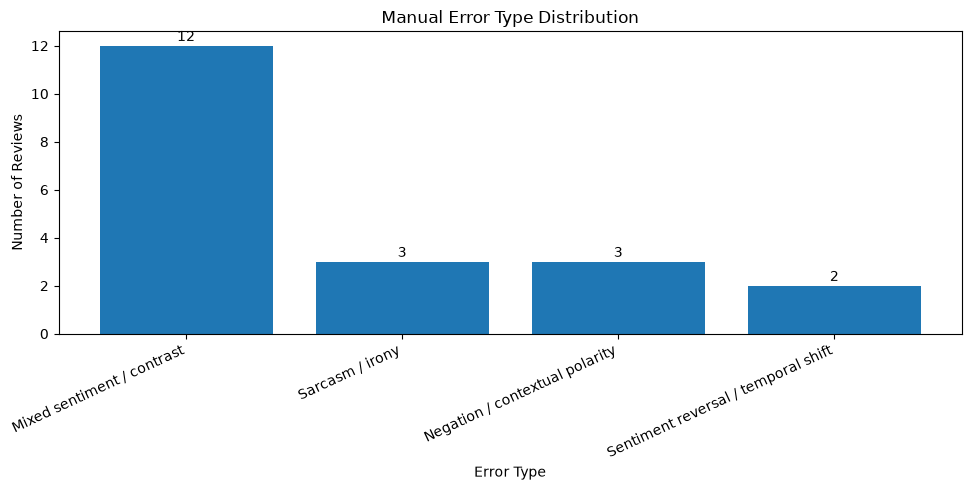

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    summary["Error Type"],
    summary["Count"]
)

plt.title("Manual Error Type Distribution")
plt.xlabel("Error Type")
plt.ylabel("Number of Reviews")

plt.xticks(rotation=25, ha="right")

for i, value in enumerate(summary["Count"]):
    plt.text(i, value + 0.2, str(value), ha="center")

plt.tight_layout()

plt.savefig(
    "manual_error_types_distribution.png",
    dpi=300
)

plt.show()

# Results and Discussion

## 1. Model Performance Comparison

Both Unigram and Bigram models were evaluated using the same 400 test reviews.

The Unigram model achieved an accuracy of 82%, while the Bigram model achieved 86%. The Bigram model also obtained higher precision, recall, and F1-score.

| Metric | Unigram | Bigram |
|---|---:|---:|
| Accuracy | 82% | 86% |
| Precision | 82.05% | 86.29% |
| Recall | 82% | 86% |
| F1-score | 81.99% | 85.97% |

These results indicate that the Bigram model performed better than the Unigram model across all evaluation metrics.

## 2. Error Analysis

A sample of 20 misclassified reviews was manually examined to identify common classification challenges.

The analysis identified four main error categories:

- Mixed sentiment and contrast: 12 reviews (60%).
- Sarcasm and irony: 3 reviews (15%).
- Negation and contextual polarity: 3 reviews (15%).
- Sentiment reversal and temporal shift: 2 reviews (10%).

Mixed sentiment and contrast represented the most frequent error category in the selected sample.

## 3. Discussion

The Bigram model outperformed the Unigram model, achieving 4 percentage points higher accuracy.

This improvement suggests that considering pairs of consecutive words can help the model capture some contextual relationships that individual words may miss.

However, both models still faced difficulties with complex language patterns, particularly mixed sentiment, sarcasm, irony, and negation.

Overall, the results demonstrate that Bigram provides better classification performance for this dataset, although more advanced contextual analysis may be needed to address complex sentiment expressions.